<a href="https://colab.research.google.com/github/Ravikumar0604/Generative_modeling_casestudy/blob/main/RMDS_Homework4_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Computer Vision Homework 1:**

In this homework you are going to remind yourself of how to use openCV to modify images.

Note that there are some outputs here, with the image used in the tutorial, but the image you are expected to use is nature.jpeg available on Canvas

1. Complete coding tasks in every cell with commented instructions.

In [12]:
# load the essential libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab.patches import cv2_imshow
import cv2
from skimage.io import imread
from PIL import Image

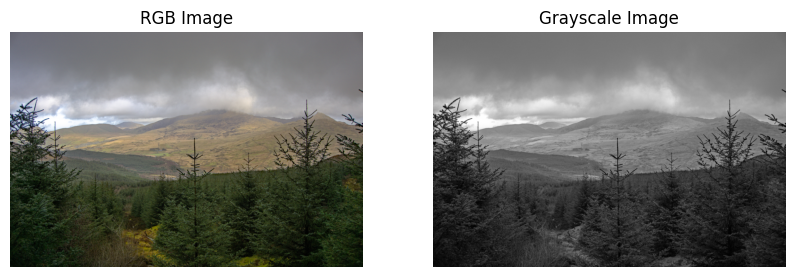

In [13]:
import os
# Use 'nature.jpeg' if available, otherwise fallback to a placeholder or prompt the user
img_path = "nature.jpeg"
if not os.path.exists(img_path):
    # Fallback to creating a dummy image or using Lena if 'nature.jpeg' isn't uploaded yet
    print("Warning: 'nature.jpeg' not found. Please upload it to Colab. Using a dummy placeholder for now.")
    # Generate a dummy image so the code doesn't fail immediately
    dummy_img = np.zeros((512, 512, 3), dtype=np.uint8)
    cv2.putText(dummy_img, 'Upload nature.jpeg', (50, 250), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 2)
    cv2.imwrite(img_path, dummy_img)

image = cv2.imread(img_path)

# Convert the color from BGR to RGB for displaying using matplotlib
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Convert RGB to grayscale
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Display them side by side
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title('RGB Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(image_gray, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off')

plt.show()

**Task:**

Before plotting the histogram,separate the colour channels of this image. R,G, B and visualise the histogram, you can also display each color channel as separate image as well as histogram of each channel.

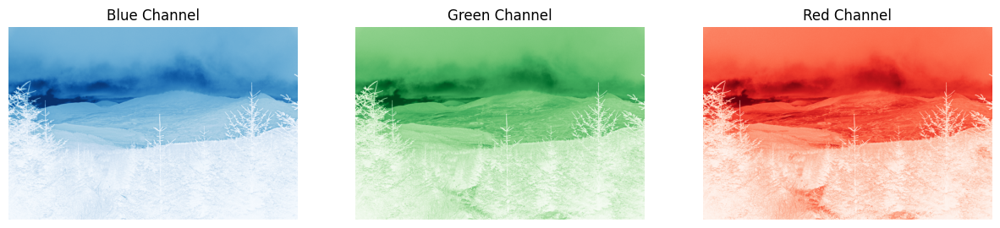

In [14]:
# Split channels (OpenCV reads images in BGR format)
b_channel, g_channel, r_channel = cv2.split(image)

# Display each color channel as a separate grayscale-like representation of intensity
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(b_channel, cmap='Blues')
axes[0].set_title('Blue Channel')
axes[0].axis('off')

axes[1].imshow(g_channel, cmap='Greens')
axes[1].set_title('Green Channel')
axes[1].axis('off')

axes[2].imshow(r_channel, cmap='Reds')
axes[2].set_title('Red Channel')
axes[2].axis('off')

plt.show()

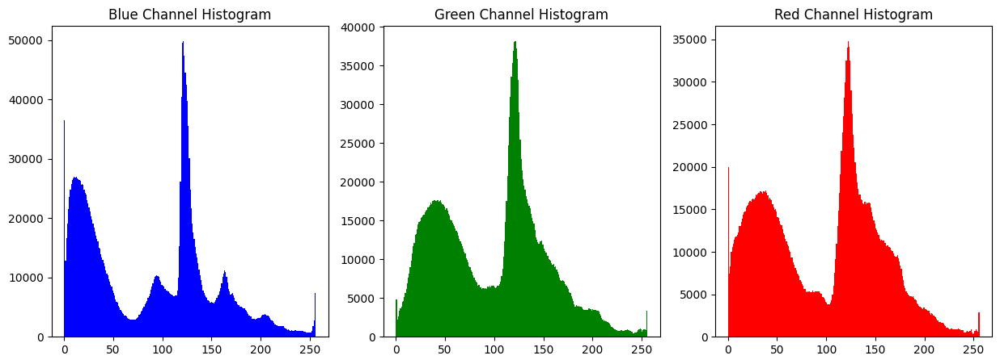

In [15]:
# Plot the histogram of each channel
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.hist(b_channel.ravel(), bins=256, range=[0, 256], color='blue')
plt.title('Blue Channel Histogram')

plt.subplot(1, 3, 2)
plt.hist(g_channel.ravel(), bins=256, range=[0, 256], color='green')
plt.title('Green Channel Histogram')

plt.subplot(1, 3, 3)
plt.hist(r_channel.ravel(), bins=256, range=[0, 256], color='red')
plt.title('Red Channel Histogram')

plt.show()

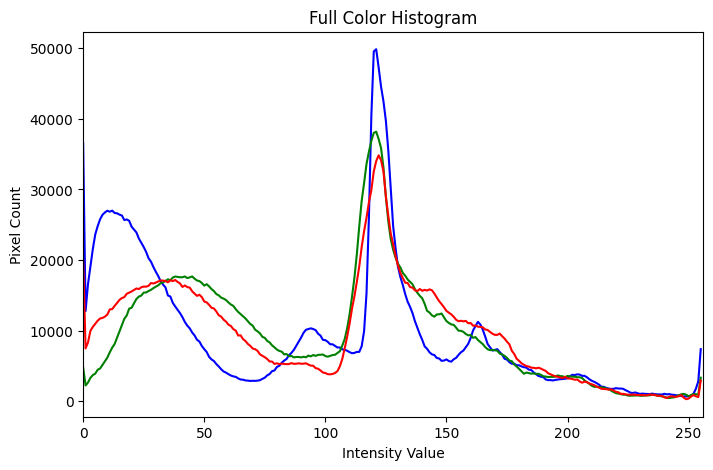

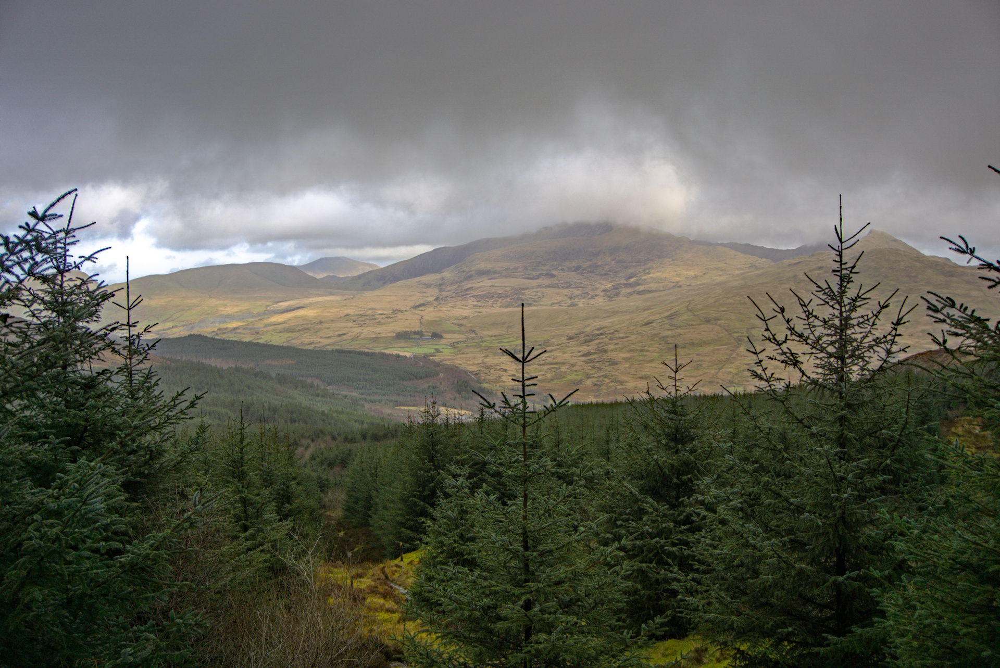

In [16]:
# Visualizing histograms of all channels in a single plot
colors = ('b', 'g', 'r')
plt.figure(figsize=(8, 5))
for i, col in enumerate(colors):
    hist = cv2.calcHist([image], [i], None, [256], [0, 256])
    plt.plot(hist, color=col)
    plt.xlim([0, 256])
plt.title('Full Color Histogram')
plt.xlabel('Intensity Value')
plt.ylabel('Pixel Count')
plt.show()

# Visualizing the loaded image
cv2_imshow(image)

Q: Explain what do you understand by the histogram? (Explain in the terms of overexposed/underexposed or left skewed image or right skewed and what does that indicate)

**Answer:**
* A **histogram** represents the distribution of pixel intensities (ranging from 0 to 255) across the image.
* **Underexposed (Left-skewed):** If the pixel counts are concentrated highly on the left side (dark values near 0), the image is dark/underexposed, lacking shadow detail.
* **Overexposed (Right-skewed):** If the pixel counts are concentrated highly on the right side (bright values near 255), the image is too bright/overexposed, resulting in washed-out highlights.
* **Low Contrast:** If the histogram has a narrow spike concentrated in the middle, the image has low contrast.
* **Equalized Histogram:** A flatter, more evenly distributed histogram indicates enhanced contrast, making details in dark and bright areas more visible.

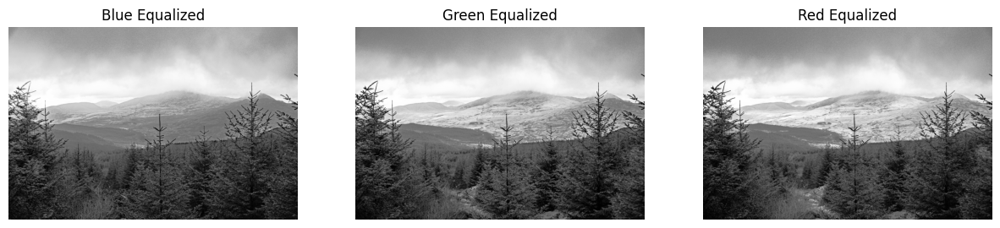

In [17]:
# Equalize each of the color channels
b_equi = cv2.equalizeHist(b_channel)
g_equi = cv2.equalizeHist(g_channel)
r_equi = cv2.equalizeHist(r_channel)

# Visualize them using Matplotlib
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(b_equi, cmap='gray')
axes[0].set_title('Blue Equalized')
axes[0].axis('off')

axes[1].imshow(g_equi, cmap='gray')
axes[1].set_title('Green Equalized')
axes[1].axis('off')

axes[2].imshow(r_equi, cmap='gray')
axes[2].set_title('Red Equalized')
axes[2].axis('off')

plt.show()

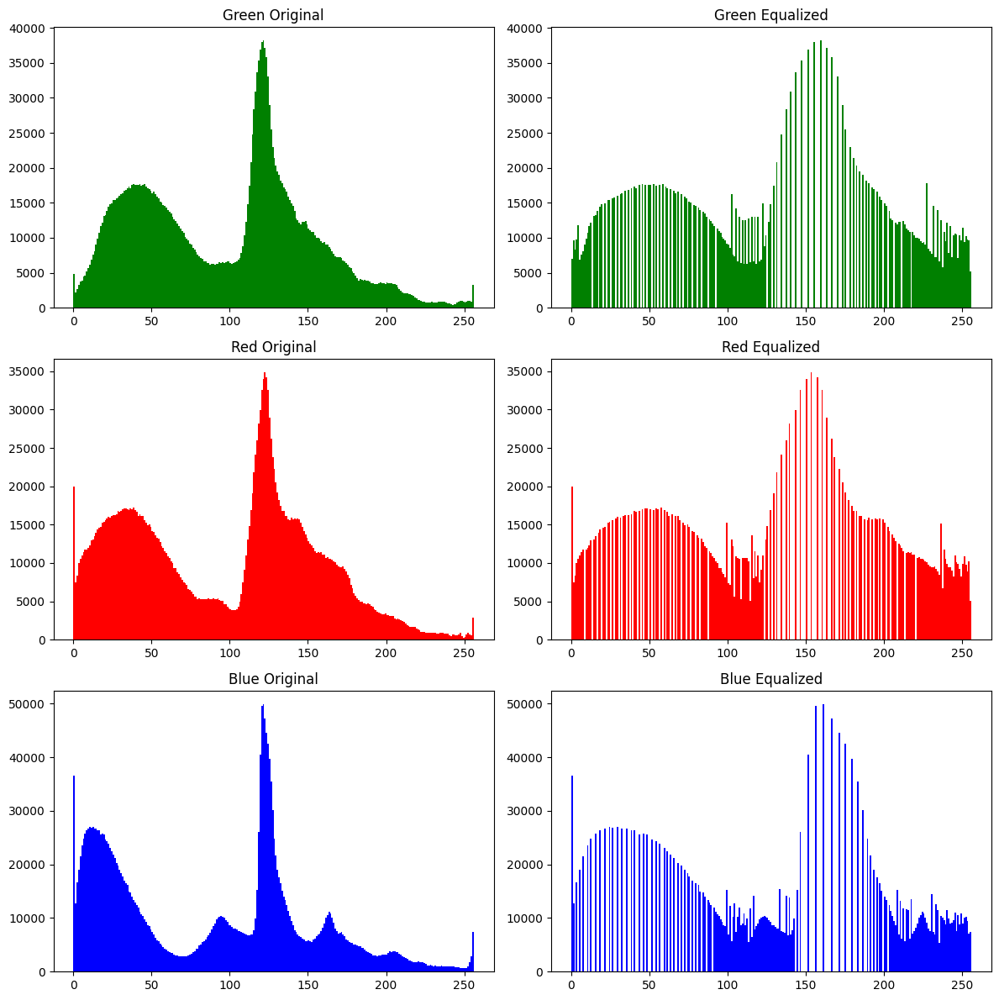

In [18]:
# Calculate histograms for each channel separately
fig, axes = plt.subplots(3, 2, figsize=(12, 12))

# Green
axes[0, 0].hist(g_channel.ravel(), bins=256, range=[0,256], color='green')
axes[0, 0].set_title('Green Original')
axes[0, 1].hist(g_equi.ravel(), bins=256, range=[0,256], color='green')
axes[0, 1].set_title('Green Equalized')

# Red
axes[1, 0].hist(r_channel.ravel(), bins=256, range=[0,256], color='red')
axes[1, 0].set_title('Red Original')
axes[1, 1].hist(r_equi.ravel(), bins=256, range=[0,256], color='red')
axes[1, 1].set_title('Red Equalized')

# Blue
axes[2, 0].hist(b_channel.ravel(), bins=256, range=[0,256], color='blue')
axes[2, 0].set_title('Blue Original')
axes[2, 1].hist(b_equi.ravel(), bins=256, range=[0,256], color='blue')
axes[2, 1].set_title('Blue Equalized')

plt.tight_layout()
plt.show()

In [19]:
# Merging the equalized channels
equi_im = cv2.merge([b_equi, g_equi, r_equi])

Original Image:


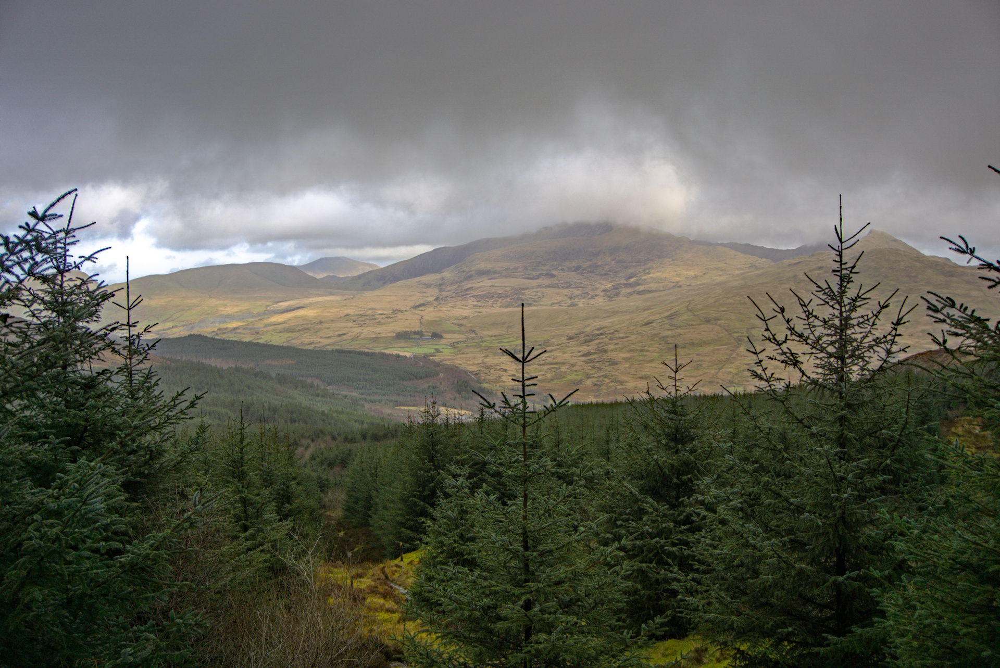

Equalized Image:


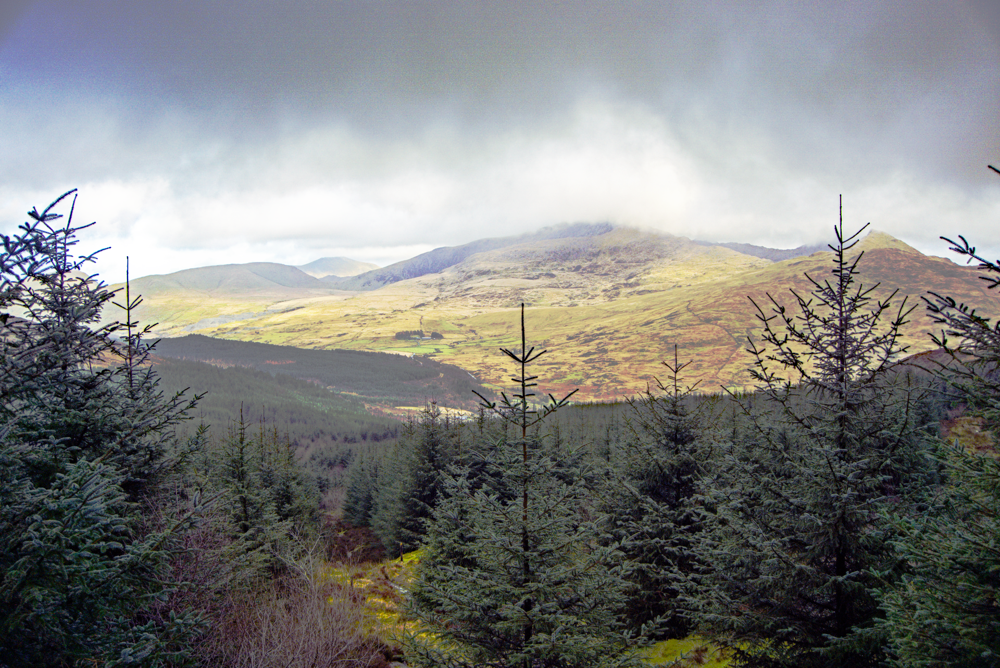

In [20]:
# Visualise the equalized image and the original image side by side
print("Original Image:")
cv2_imshow(image)
print("Equalized Image:")
cv2_imshow(equi_im)